# Fine-Tuning an Embedding Model on Memory Traces: Better Retrieval, Safely Deployed

**Calderwood Insurance**, the claims desk, September 2026. A handler asks Ada:

> *"How much goodwill can a handler give without asking anyone?"*

The answer is in Ada's memory. Dev taught it to her on 1 September, and it is
memory unit `mem_0001`: *"Handlers can approve goodwill payments up to £250
from the GDR."* But Ada's memory search doesn't put it first. It puts the
**Desk Lead's** limit first: *"A Desk Lead can approve goodwill payments up to
£1,000."* Same words, same topic, four times the money.

Nothing is wrong with the memory. What is wrong is the model that turns text
into vectors: it was trained on the public web, and to it *goodwill*,
*handler*, *Desk Lead* and *approve* are all the same neighbourhood. It has
never seen Calderwood.

This notebook fine-tunes that model, `BAAI/bge-small-en-v1.5`, on the
contrastive pairs notebook 01 built from Ada's traces. It measures what
changed on Calderwood's held-out questions and on a general retrieval
benchmark the training never saw, then deploys the new model the way a
production team should: a versioned directory, a re-built index, a promotion
check, and a pointer that can be switched back.

It is the second of four notebooks in `beyond_the_context_window/`. It runs on
a laptop (Apple Silicon or a single NVIDIA GPU, or slowly on CPU) and needs no
API key.

## Key takeaways

- ***An embedder is the model that decides what the answering model sees.*** *Fixing it fixes retrieval for every question at once, without touching the memory or the large model.*
- ***Hard negatives teach the distinction that matters.*** *In-batch negatives teach "goodwill, not sanctions"; a hard negative teaches "the handler's limit, not the Desk Lead's".*
- ***Measure lift and regression together.*** *Lift on your own questions says the model learned something; no regression on a general benchmark says it didn't forget something else to do it.*
- ***A new embedder means a new index.*** *Vectors from two models can't be compared, so every memory unit is re-embedded, and the index records which model made it.*
- ***Promotion is a rule written before the numbers, and rollback is a pointer.*** *The old model and its index stay on disk, so going back takes one write and no re-embedding.*
- ***At 33 million parameters, full fine-tuning is the simple choice.*** *For embedders in the hundreds of millions of parameters and up, LoRA trains a small adapter instead.*

## How this notebook is organised

| Part | What happens | What you have at the end |
|---|---|---|
| **1 · The use case** | A search that finds the wrong limit, and what fine-tuning an embedder changes | The problem, the vocabulary and the architecture |
| **2 · The measuring stick** | Relevance labels from the held-out questions, three metrics, and the base model on Calderwood and on SciFact | The "before" numbers |
| **3 · Fine-tuning** | Contrastive training with in-batch and hard negatives, then lift and regression; an optional LoRA run on a larger embedder | A candidate model, and the evidence for and against it |
| **4 · Deploying it safely** | Versions, re-indexing, a promotion check and a rollback drill | An active model that notebook 03 retrieves with, and a way back |

### ⭐ The live path

About twenty minutes. Training takes seconds and the SciFact runs about a
minute each, so the whole notebook can run live; on a slow machine, run it
beforehand and show the saved outputs.

| Stop | Section | What to show | Minutes |
|---|---|---|---|
| 1 | 1.1 ⭐ The wrong limit, ranked first | The problem in one search | 2 |
| 2 | 1.3 ⭐ The reference architecture | Training path and serving path on one diagram | 2 |
| 3 | 2.4 ⭐ The base model on Calderwood | The "before" numbers, and which questions it misses | 3 |
| 4 | 3.2 ⭐ Train it | Full fine-tuning in seconds: the settings and the loss | 3 |
| 5 | 3.3 ⭐ Lift on Calderwood | Before and after, per category, and the misses that were fixed | 3 |
| 6 | 3.4 ⭐ Regression on SciFact | The general benchmark, before and after | 2 |
| 7 | 4.3 ⭐ The promotion check | The rule, the numbers and the verdict | 2 |
| 8 | 4.4 ⭐ Rollback | One question, three answers: v1, rolled back to v0, forward to v1 | 3 |

# Part 1 · The use case

This part is the *why*: what went wrong in Ada's search, what an embedding
model is and what fine-tuning it changes, and the architecture the rest of the
notebook builds. No code runs here.

## 1.1 ⭐ The wrong limit, ranked first

Ada's memory search works like most: each memory unit is turned into a vector
once, when it is written; each question is turned into a vector when it is
asked; and the units whose vectors are closest to the question's go into the
context. The model doing the turning is the **embedder**.

On the goodwill question, the base embedder ranks the Desk Lead's £1,000 unit
above the handler's £250 unit. Section 2.4 shows it is not the only miss:
*"A customer on the phone seems really distressed and confused. Which flag
should I set?"* ranks the sanctions-match error `RFN-110` above the Rapid
Vulnerability Flag: to a general-purpose model, a flag on a customer is a flag
on a customer.

A large answering model can sometimes recover from a bad ranking if the right
unit is still in the top three. It can't recover from a unit that never
arrives, and it will happily quote a wrong limit that does.

## 1.2 · What fine-tuning an embedder changes

| Changes | Doesn't change |
|---|---|
| The vector every question and every memory unit gets | The memory units themselves |
| Which units rank first for a question | The answering model, its prompt and its cost |
| Every index built with the old model, which has to be rebuilt | The number of units retrieved, or the context budget |

So the change is small in one sense (one model of 33 million parameters, a
few seconds of training) and large in another: every stored vector is now
stale. Part 4 is about that.

**Full fine-tuning or LoRA?** `bge-small-en-v1.5` has 33 million parameters.
Updating all of them takes seconds and a few hundred megabytes, so this
notebook does full fine-tuning: it is simpler, and it has nothing to merge or
load at serving time. For a larger embedder (`Qwen3-Embedding-0.6B` has 600
million parameters, and 4B and 8B versions exist) **LoRA** is the usual
choice: it freezes the model and trains small low-rank matrices beside its
layers, a few million parameters instead of hundreds of millions, so the
optimiser's memory and the saved artefact are both small. Section 3.5 shows
it on `Qwen3-Embedding-0.6B`.

## 1.3 ⭐ The reference architecture

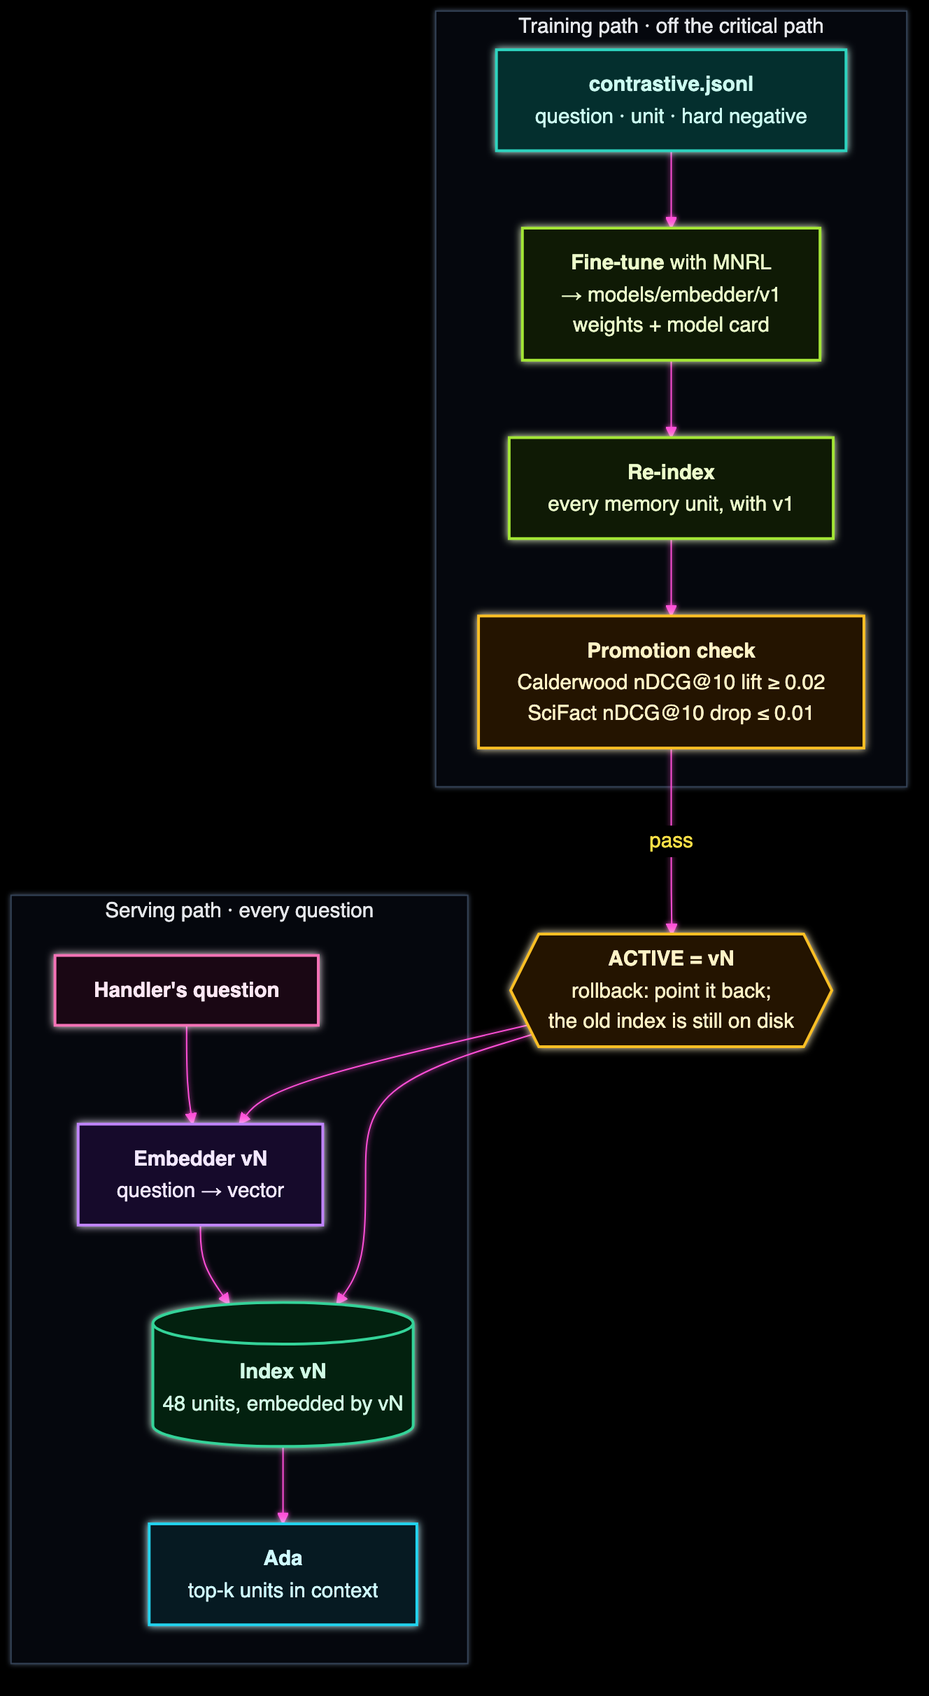

**How to read it.** The upper box is the training path, off the handler's
critical path: contrastive pairs from notebook 01 train a candidate, the
candidate re-embeds every memory unit into its own index, and the promotion
check decides whether the pointer moves. The lower box is the serving path, on
every question: the embedder named by `ACTIVE` turns the question into a
vector, the index built by the same version returns the closest units, and
they go into Ada's context. The hexagon is the pointer, and it is the only
thing that connects the two paths.

The terms, each defined once:

- **An embedding is a fixed-length vector for a text.** Two texts with similar meanings get vectors that point in similar directions; the score is the cosine of the angle between them.
- **An index is the stored embeddings of every memory unit, made by one model.** Calderwood's has 48 rows.
- **nDCG@10** (*normalised discounted cumulative gain*) **scores a ranking from 0 to 1**, giving more credit for relevant units near the top and dividing by the best possible ranking. 1.0 means every relevant unit is ranked first.
- **Recall@5 is the share of a question's relevant units that appear in the top five.** It answers *"did the right unit reach the context?"* when five units are retrieved.
- **MRR** (*mean reciprocal rank*) **averages 1 / (the rank of the first relevant unit)**: 1.0 if it is first, 0.5 if second, 0.33 if third.
- **Lift is the change in a metric on Calderwood's held-out questions; regression is a fall on a general benchmark the training never saw.**
- **The active version is the model the serving path uses, named by a pointer file.** Rollback is changing the pointer.

> ### 📌 Key Takeaways
> - The embedder decides what reaches the answering model; a general-purpose one can't tell Calderwood's near-identical units apart.
> - Fine-tuning changes every vector, so it means re-indexing every unit.
> - Full fine-tuning suits a 33M-parameter embedder; LoRA suits the large ones.

# Part 2 · The measuring stick

Before training anything, decide how to measure it and measure the base
model. This part builds relevance labels from the held-out questions, writes
the three metrics, and runs the base model on Calderwood and on SciFact. By the
end you have the numbers every later number is compared with.

## 2.1 · Setup

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `DEVICE` | Notebook setting | `mps` on Apple Silicon, `cuda` on an NVIDIA GPU, otherwise `cpu` | Everything below runs on whichever is present |
| `BASE_MODEL` | Notebook setting | `BAAI/bge-small-en-v1.5`, a 33M-parameter English embedder | Small enough to fine-tune fully in seconds, and well studied |
| `QUERY_PROMPT` | Notebook setting | The instruction BGE models put before a short query: *"Represent this sentence for searching relevant passages: "* | Questions get it, memory units don't. Training uses the same split, so serving and training agree |
| `cw` (`calderwood_world`) | Calderwood world | Calderwood's shared facts | The model card records which round of Calderwood's knowledge the index holds |
| `units`, `held_out`, `pairs` | Data | The 48 memory units, the 61 held-out questions, and the 240 contrastive pairs from notebook 01 | The index, the test and the training set |

In [1]:
import gc
import json
import os
import random
import shutil
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

# Cap what PyTorch may take from a Mac's shared memory (set before torch is imported).
os.environ.setdefault("PYTORCH_MPS_HIGH_WATERMARK_RATIO", "0.5")
os.environ.setdefault("PYTORCH_MPS_LOW_WATERMARK_RATIO", "0.4")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TQDM_DISABLE"] = "1"                      # no progress bars in the saved outputs
warnings.filterwarnings("ignore", message=".*IProgress.*")

**Then the libraries**, with their progress bars and routine warnings turned
down so the outputs below show results, and the device chosen.

In [2]:
import numpy as np
import pandas as pd
import torch
from huggingface_hub import snapshot_download
from huggingface_hub.utils import disable_progress_bars
from huggingface_hub.utils import logging as hub_logging
from transformers.utils import logging as hf_logging

import calderwood_world as cw  # the shared Calderwood world, beside this notebook

disable_progress_bars(); hf_logging.disable_progress_bar(); hf_logging.set_verbosity_error(); hub_logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=DeprecationWarning)
DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
SEED = 7
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("device:", DEVICE, "| torch", torch.__version__)

device: mps | torch 2.13.0


In [3]:
DATA = Path("..") / "data" / "calderwood"
DATASETS = Path("datasets")
MODELS = Path("models") / "embedder"
BASE_MODEL = "BAAI/bge-small-en-v1.5"
QUERY_PROMPT = "Represent this sentence for searching relevant passages: "


def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


units = read_jsonl(DATA / "memory_units.jsonl")
held_out = read_jsonl(DATA / "eval.jsonl")
pairs = read_jsonl(DATASETS / "contrastive.jsonl")
UNIT = {u["memory_id"]: u for u in units}
BY_REF = {u["kb_ref"]: u["memory_id"] for u in units}
print(f"{len(units)} memory units, {len(held_out)} held-out questions, {len(pairs)} contrastive pairs")

48 memory units, 61 held-out questions, 240 contrastive pairs


## 2.2 · Relevance labels from the held-out questions

A retrieval metric needs to know, for each question, which units are the right
ones. The held-out questions don't list memory ids, but their ids say which
fact they test, and the units say which fact they hold:

- **A single-fact question's id is `eval_<fact id>`**, and the unit holding that
  fact has the same id in its `kb_ref` field. `eval_gdr_handler` is answered by
  the unit whose `kb_ref` is `gdr_handler` (`mem_0001`). That covers 48
  questions, one per unit.
- **The eight multi-hop questions** are `eval_multi_hop_1` to `_8`, and their
  ids name no fact. Their relevant units are the facts the answer needs, listed
  by hand below with the reason. (A mechanical rule, *"every unit that contains
  one of the question's key terms"*, overreaches: `surveyor` also appears in
  the status code Q7, which answers nothing here.)
- **The five prior-knowledge questions** (*"What is the capital of Japan?"*)
  have no relevant unit, so they are left out of retrieval scoring. Notebook 03
  uses them to check that a trained answering model hasn't forgotten things.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `MULTI_HOP` | Data | The fact ids each multi-hop question needs | The only relevance labels written by hand |
| `qrels` | Data | Question id → the set of relevant memory ids (*qrels* is the information-retrieval name for relevance judgements) | What every metric below is computed against |

In [4]:
MULTI_HOP = {
    "eval_multi_hop_1": ["tpa_g2", "tpa_senior"],        # £12,500 is over a Grade 2's £10,000, so a Senior
    "eval_multi_hop_2": ["llu", "eow_15k"],              # over £50,000 goes to the LLU; escape of water needs HSR
    "eval_multi_hop_3": ["gdr_desklead", "gdr_hco"],     # a Desk Lead stops at £1,000; above that, the HCO
    "eval_multi_hop_4": ["green_lane"],                  # under £1,500 with no injury is Green Lane
    "eval_multi_hop_5": ["q9"],                          # Q9 is never disclosed: "under review"
    "eval_multi_hop_6": ["rfn110"],                      # RFN-110 goes to Financial Crime
    "eval_multi_hop_7": ["ibnr", "ibnr_48"],             # a broker-placed mid-term change needs an IBNR, in 48 hours
    "eval_multi_hop_8": ["motor_tl"],                    # 10 working days from the salvage decision
}
qrels = {}
for q in held_out:
    if q["category"] == "prior_knowledge":
        continue
    refs = MULTI_HOP.get(q["id"], [q["id"].removeprefix("eval_")])
    qrels[q["id"]] = {BY_REF[r] for r in refs}
QIDS, QTEXT = list(qrels), {q["id"]: q["question"] for q in held_out}
CATEGORY = {q["id"]: q["category"] for q in held_out}
print(len(qrels), "questions scored;", sum(len(r) > 1 for r in qrels.values()), "with two relevant units;",
      sum(len(r) for r in qrels.values()), "relevance labels")

56 questions scored; 4 with two relevant units; 60 relevance labels


## 2.3 · Three metrics, written out

Libraries compute these, but each is a few lines, and writing them out makes
the numbers readable. Every vector is normalised to length 1, so a dot product
is the cosine similarity, and a matrix product scores every question against
every unit at once.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `retrieval_metrics(qids, q_vecs, doc_ids, d_vecs, qrels)` | Notebook helper | Ranks every document for every question; returns mean nDCG@10, Recall@5 and MRR | Used for Calderwood and SciFact alike, so the two are measured the same way |
| `embed(model, texts, query=False)` | Notebook helper | Embeds texts, adding `QUERY_PROMPT` to queries, normalised to length 1 | One function, so the base and fine-tuned models are always called identically |

In [5]:
def retrieval_metrics(qids, q_vecs, doc_ids, d_vecs, qrels, k=10):
    """Mean nDCG@10, Recall@5 and MRR over the questions; vectors are unit length, so a dot product is a cosine."""
    scores = q_vecs @ d_vecs.T
    ndcg, recall, mrr = [], [], []
    for i, qid in enumerate(qids):
        relevant = qrels[qid]
        ranked = [doc_ids[j] for j in np.argsort(-scores[i])[:k]]
        gain = sum(1 / np.log2(r + 2) for r, d in enumerate(ranked) if d in relevant)
        ideal = sum(1 / np.log2(r + 2) for r in range(min(len(relevant), k)))
        ndcg.append(gain / ideal)
        recall.append(len(relevant & set(ranked[:5])) / len(relevant))
        mrr.append(next((1 / (r + 1) for r, d in enumerate(ranked) if d in relevant), 0.0))
    return {"nDCG@10": float(np.mean(ndcg)), "Recall@5": float(np.mean(recall)), "MRR": float(np.mean(mrr))}


def embed(model, texts, query=False):
    texts = [QUERY_PROMPT + t for t in texts] if query else list(texts)
    return model.encode(texts, batch_size=32, normalize_embeddings=True, convert_to_numpy=True)

## 2.4 ⭐ The base model on Calderwood

Now the base embedder on the 56 scored questions against the 48 units: the
overall metrics, the same by category, and every question whose first relevant
unit is *not* ranked first, with the unit that was.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `SentenceTransformer(name, device=)` | sentence-transformers API | Loads an embedding model with its tokenizer and pooling | The same object is trained in Part 3 |
| `calderwood_eval(model)` | Notebook helper | Embeds the questions and units; returns the metrics and the score matrix | Run once per model version |
| `by_category(scores)`, `misses(scores)` | Notebook helpers | nDCG@10 per question category; the questions whose top unit is wrong | Where the average comes from |

In [6]:
from sentence_transformers import SentenceTransformer

DOC_IDS = [u["memory_id"] for u in units]


def calderwood_eval(model):
    q_vecs = embed(model, [QTEXT[q] for q in QIDS], query=True)
    d_vecs = embed(model, [UNIT[d]["content"] for d in DOC_IDS])
    return retrieval_metrics(QIDS, q_vecs, DOC_IDS, d_vecs, qrels), q_vecs @ d_vecs.T


def first_relevant_rank(scores, i):
    ranked = [DOC_IDS[j] for j in np.argsort(-scores[i])]
    return min(ranked.index(d) for d in qrels[QIDS[i]]) + 1, ranked[0]


base = SentenceTransformer(BASE_MODEL, device=DEVICE)
base_cw, base_scores = calderwood_eval(base)
print({k: round(v, 3) for k, v in base_cw.items()})

{'nDCG@10': 0.857, 'Recall@5': 0.946, 'MRR': 0.826}


In [7]:
def by_category(scores):
    rows = []
    for i, qid in enumerate(QIDS):
        rank, _ = first_relevant_rank(scores, i)
        rows.append({"category": CATEGORY[qid], "first relevant at rank 1": rank == 1})
    return pd.DataFrame(rows).groupby("category")["first relevant at rank 1"].agg(["sum", "count"])


def misses(scores):
    out = []
    for i, qid in enumerate(QIDS):
        rank, top = first_relevant_rank(scores, i)
        if rank > 1:
            out.append({"question": QTEXT[qid][:70], "right unit at rank": rank, "ranked first instead": UNIT[top]["kb_ref"]})
    return pd.DataFrame(out)


print(by_category(base_scores).T.to_string(), "\n")
print(misses(base_scores).to_string(index=False))

category  abbreviation  collision  error_code  multi_hop  policy  status_code  system
sum                  9          5           5          6      10            4       3
count               13          5           5          8      15            4       6 

                                                              question  right unit at rank ranked first instead
A customer on the phone seems really distressed and confused. Which fl                   4               rfn110
      The account notes say the client is PCL. What does that tell me?                   6                  kad
I think a claim might be fraudulent. What do I need to fill in, and wh                   4                   q3
What's the time limit for getting a fraud referral to the Counter Frau                   2                  cfu
Which desk at Calderwood deals with escalations from our top commercia                   5                  pcl
How quickly must an Internal Broker Notification Request go in after

**How to read the result.**

- **The base model is already good: nDCG@10 0.857, Recall@5 0.946, MRR 0.826.**
  For 42 of the 56 questions the right unit is ranked first (the `sum` row adds
  to 42). A general-purpose embedder gets the topic right most of the time.
- **The misses are near neighbours.** The handler's goodwill question ranks
  the Desk Lead's limit first; the distressed-customer question ranks
  `RFN-110` first; the PCL question ranks the Key Accounts Desk first, and the
  Key Accounts Desk question ranks PCL first. Each wrong unit shares the right
  one's words. These are the confusions hard negatives are built for.
- **Two misses are far down.** *"I need to check a customer's cover
  dates. Which system do I use?"* puts Atlas at rank 41 and the FNOL deadline question puts its unit at
  rank 27, both behind Q3 (*awaiting documents*). Here the question and the
  unit share almost no words: *cover dates* against *policy administration
  system*. That is vocabulary, not a near neighbour.
- **By category, `system` is weakest (3 of 6 first) and `policy` next (10 of 15).**

## 2.5 · The base model on SciFact

Lift on Calderwood is only half the evidence. The other half is whether
training made the model worse at retrieval in general. **SciFact** is a public
benchmark from the BEIR suite: 300 test claims about scientific findings, a
corpus of 5,183 paper abstracts, and human judgements of which abstracts
support or refute each claim. Nothing in it is about insurance, which is the
point: a model that has over-fitted to Calderwood will show it here.

The files are read with pandas from the Hugging Face Hub (the corpus and
queries are Parquet; the judgements are a tab-separated file), at pinned
revisions so the benchmark can't change under the comparison.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `snapshot_download(repo, revision=, allow_patterns=)` | Hugging Face Hub API | Returns a local folder for a dataset at an exact revision, from the cache when it's there | Pinned, so a later run reads byte-identical files |
| `corpus`, `queries`, `sci_qrels` | Data | 5,183 abstracts (title plus text), the claims, and the test judgements | The general benchmark |
| `scifact_eval(model)` | Notebook helper | Embeds the corpus and the 300 test claims and returns the three metrics | Run for the base model now and the candidate in Part 3 |

In [8]:
SCIFACT = snapshot_download("BeIR/scifact", repo_type="dataset", allow_patterns=["corpus/*", "queries/*"],
                            revision="b3b5335604bf5ee3c4447671af975ea25143d4f5")
SCIFACT_QRELS = snapshot_download("BeIR/scifact-qrels", repo_type="dataset", allow_patterns=["test.tsv"],
                                  revision="2938d17dc3b09882fdb8c12bbbe2e2dc0e75a029")
corpus = pd.read_parquet(next(Path(SCIFACT).glob("corpus/*.parquet")))
queries = pd.read_parquet(next(Path(SCIFACT).glob("queries/*.parquet")))
judged = pd.read_csv(Path(SCIFACT_QRELS) / "test.tsv", sep="\t", dtype=str)
sci_qrels = judged.groupby("query-id")["corpus-id"].apply(set).to_dict()
SCI_QIDS = sorted(sci_qrels)
SCI_QTEXT = dict(zip(queries["_id"].astype(str), queries["text"]))
SCI_DOC_IDS = corpus["_id"].astype(str).tolist()
SCI_DOCS = (corpus["title"].fillna("") + " " + corpus["text"].fillna("")).str.strip().tolist()
print(f"SciFact: {len(SCI_DOCS):,} abstracts, {len(SCI_QIDS)} test claims, {len(judged)} judgements")

SciFact: 5,183 abstracts, 300 test claims, 339 judgements


In [9]:
def scifact_eval(model):
    d_vecs = embed(model, SCI_DOCS)
    q_vecs = embed(model, [SCI_QTEXT[q] for q in SCI_QIDS], query=True)
    return retrieval_metrics(SCI_QIDS, q_vecs, SCI_DOC_IDS, d_vecs, sci_qrels)


t0 = time.perf_counter()
base_sci = scifact_eval(base)
print({k: round(v, 3) for k, v in base_sci.items()}, f"in {time.perf_counter() - t0:.0f} s")

{'nDCG@10': 0.713, 'Recall@5': 0.759, 'MRR': 0.682} in 46 s


**How to read the result.** nDCG@10 0.713 on SciFact, close to the figure
published for this model on the MTEB leaderboard (about 0.71), so the
evaluation code agrees with the standard one. Embedding 5,183 abstracts took
most of the 46 seconds; every SciFact run below costs the same again.

> ### 📌 Key Takeaways
> - Relevance comes from the held-out ids: `eval_<fact id>` matches a unit's `kb_ref`; the eight multi-hop questions are labelled by hand.
> - The base model already ranks most Calderwood questions well; its misses are near neighbours, which is what hard negatives are for.
> - SciFact is the regression check: same metrics, a domain the training never sees.

# Part 3 · Fine-tuning

This part trains a candidate on notebook 01's contrastive pairs and measures
it twice: on Calderwood for lift and on SciFact for regression. An optional
section repeats the training with LoRA on a 600M-parameter embedder.

## 3.1 · The training set and the loss

**MultipleNegativesRankingLoss** (MNRL) is the standard loss for this job.
For each question in a batch it scores the question against every positive in
the batch and every hard negative, and asks the right positive to win, as a
classification over all of them. So a batch of 16 rows gives each question 15
*in-batch negatives* (the other questions' positives) for free, plus the hard
negative its row brings.

Two details decide whether that works on Calderwood's data:

- **One hard negative per row.** Notebook 01 kept the three nearest neighbours;
  this run uses the nearest one. Each row then brings two memory units, so a
  batch of 16 rows needs 32 distinct units out of 48. With three negatives it
  would need 64, and the batches couldn't be filled without repeats.
- **No duplicates in a batch.** Each unit is the positive for five different
  questions. If two of them landed in one batch, each would treat the other's
  positive (the *same* unit) as a negative, and the loss would push a question
  away from its own answer. The `NO_DUPLICATES` batch sampler builds batches in
  which no text appears twice.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `Dataset.from_list(rows)` | Hugging Face `datasets` API | Builds a training set from dicts | Columns `anchor`, `positive`, `negative`: the order MNRL expects |
| `MultipleNegativesRankingLoss(model)` | sentence-transformers API | The loss described above | In-batch negatives plus the hard negative |
| `BatchSamplers.NO_DUPLICATES` | sentence-transformers API | Batches with no repeated text | Stops a unit being its own question's negative |

In [10]:
from datasets import Dataset

train_set = Dataset.from_list([{"anchor": p["anchor"], "positive": p["positive"], "negative": p["negatives"][0]}
                               for p in pairs])
print(train_set)
print("example:", {k: v[:70] for k, v in train_set[0].items()})

Dataset({
    features: ['anchor', 'positive', 'negative'],
    num_rows: 240
})
example: {'anchor': 'What is the Total Payout Authority for Grade 1?', 'positive': "A Grade 1 handler's TPA is £2,500.", 'negative': "A Grade 2 handler's TPA is £10,000."}


## 3.2 ⭐ Train it

Full fine-tuning: every one of the model's parameters is updated. The settings
are conventional for a small embedder and a small dataset; they are listed
here so the model card can record them.

| Setting | Value | Why |
|---|---|---|
| Epochs | 3 | 240 rows is small; three passes is enough to move the model without memorising |
| Batch size | 16 | Fifteen in-batch negatives per question, with room to fill batches without duplicates |
| Learning rate | 3e-5, warm-up over the first 10% of steps | Low enough that the model keeps what it knew |
| Precision | fp32 | 33M parameters train in seconds without bf16 |
| `prompts` | `QUERY_PROMPT` on the `anchor` column | Training sees questions exactly as serving will |

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `SentenceTransformerTrainingArguments(...)` | sentence-transformers API | The settings above, plus logging and seeding | `save_strategy="no"`: the model is saved once, deliberately, in Part 4 |
| `SentenceTransformerTrainer(model=, args=, train_dataset=, loss=)` | sentence-transformers API | The training loop | Standard Hugging Face trainer underneath |
| `PrinterCallback` | Transformers API | Prints every log line | Removed, so the cell prints one short loss table instead |

In [11]:
from sentence_transformers import SentenceTransformerTrainer, SentenceTransformerTrainingArguments
from sentence_transformers.sentence_transformer.losses import MultipleNegativesRankingLoss
from sentence_transformers.sentence_transformer.training_args import BatchSamplers
from transformers import PrinterCallback

SETTINGS = {"epochs": 3, "batch_size": 16, "learning_rate": 3e-5, "warmup": 0.1, "hard_negatives_per_row": 1}
candidate = SentenceTransformer(BASE_MODEL, device=DEVICE)
args = SentenceTransformerTrainingArguments(
    output_dir="runs/embedder", num_train_epochs=SETTINGS["epochs"], per_device_train_batch_size=SETTINGS["batch_size"],
    learning_rate=SETTINGS["learning_rate"], warmup_steps=SETTINGS["warmup"], batch_sampler=BatchSamplers.NO_DUPLICATES,
    prompts={"anchor": QUERY_PROMPT}, seed=SEED, logging_steps=5, save_strategy="no", report_to="none", disable_tqdm=True,
    dataloader_pin_memory=False)
trainer = SentenceTransformerTrainer(model=candidate, args=args, train_dataset=train_set,
                                     loss=MultipleNegativesRankingLoss(candidate))
trainer.remove_callback(PrinterCallback)
t0 = time.perf_counter()
trainer.train()
train_seconds = time.perf_counter() - t0
losses = [(round(h["epoch"], 2), round(h["loss"], 3)) for h in trainer.state.log_history if "loss" in h]
print(f"{sum(p.numel() for p in candidate.parameters()):,} parameters trained in {train_seconds:.0f} s on {DEVICE}")
print("loss by epoch:", losses)

33,360,000 parameters trained in 10 s on mps
loss by epoch: [(0.33, 0.993), (0.67, 0.74), (1.0, 0.489), (1.33, 0.411), (1.67, 0.322), (2.0, 0.285), (2.33, 0.343), (2.67, 0.222), (3.0, 0.104)]


**How to read the result.**

- **33,360,000 parameters, all of them trained, in about 10 seconds.** That is
  what full fine-tuning means here, and why it is the simple choice at this
  size.
- **The loss falls from 0.99 to 0.10 over three epochs.** It is logged every
  five batches, so it bounces (0.285, then 0.343); the trend is what matters.
  A low training loss says the model now ranks the right unit first for the
  *training* questions. It says nothing yet about the held-out ones, which is
  the next cell's job.

## 3.3 ⭐ Lift on Calderwood

The same three metrics on the same 56 questions, before and after, then the
per-category view and the misses that remain. Nothing new is defined.

In [12]:
cand_cw, cand_scores = calderwood_eval(candidate)
lift = pd.DataFrame({"base": base_cw, "fine-tuned": cand_cw}).T.round(3)
lift.loc["change"] = (lift.loc["fine-tuned"] - lift.loc["base"]).round(3)
print(lift.to_string(), "\n")
both = by_category(base_scores).join(by_category(cand_scores), lsuffix=" base", rsuffix=" tuned")
print(both[["sum base", "sum tuned", "count base"]].rename(columns={"count base": "questions"}).T.to_string(), "\n")
print(misses(cand_scores).to_string(index=False))

            nDCG@10  Recall@5    MRR
base          0.857     0.946  0.826
fine-tuned    0.955     1.000  0.943
change        0.098     0.054  0.117 

category   abbreviation  collision  error_code  multi_hop  policy  status_code  system
sum base              9          5           5          6      10            4       3
sum tuned            12          5           5          7      14            4       4
questions            13          5           5          8      15            4       6 

                                                              question  right unit at rank ranked first instead
I think a claim might be fraudulent. What do I need to fill in, and wh                   2                  cfu
                     Which system should I open to record a new claim?                   2                tally
      I need to check a customer's cover dates. Which system do I use?                   4         rvf_callback
After a customer first reports a loss, how long do I

**How to read the result.**

- **Every metric rises.** nDCG@10 0.857 → 0.955 (+0.098), MRR 0.826 → 0.943,
  and Recall@5 0.946 → 1.000: every relevant unit for every question is now in
  the top five, which is what reaches Ada's context.
- **Right unit first: 42 → 51 of 56.** The gains are in `abbreviation` (9 →
  12), `policy` (10 → 14), `system` (3 → 4) and `multi_hop` (6 → 7). The
  goodwill question from 1.1 is no longer a miss: the handler's £250 limit now
  ranks above the Desk Lead's.
- **The far misses came close.** *Cover dates* moved from rank 41 to 4, and the
  FNOL deadline from 27 to 5. Neither reached first place: the training
  questions didn't use those words either.
- **One question got slightly worse.** The cracked-windscreen question had
  Green Lane at rank 2 and now has it at rank 3, behind the Grade 1 limit. A
  fine-tune moves every vector, so a gain for most questions can come with a
  loss for one. This is why the comparison is per question as well as on
  average.

## 3.4 ⭐ Regression on SciFact

The candidate on the general benchmark. The corpus is re-embedded with the
candidate, because the base model's vectors can't be compared with its
questions.

In [13]:
t0 = time.perf_counter()
cand_sci = scifact_eval(candidate)
regression = pd.DataFrame({"base": base_sci, "fine-tuned": cand_sci}).T.round(4)
regression.loc["change"] = (regression.loc["fine-tuned"] - regression.loc["base"]).round(4)
print(regression.to_string(), f"\n({time.perf_counter() - t0:.0f} s)")

            nDCG@10  Recall@5     MRR
base         0.7127    0.7590  0.6822
fine-tuned   0.7159    0.7643  0.6870
change       0.0032    0.0053  0.0048 
(46 s)


**How to read the result.** SciFact nDCG@10 went from 0.7127 to 0.7159, and
Recall@5 and MRR rose by about the same. No regression; if anything a rise,
though a change of 0.003 on 300 claims is within the noise. Forty-five small
steps at a low learning rate taught the model Calderwood's distinctions
without moving what it knew about scientific abstracts.

## 3.5 · Optional: LoRA on a larger embedder

`Qwen3-Embedding-0.6B` is eighteen times the size of `bge-small`. Full
fine-tuning it would need optimiser state for 600 million parameters; LoRA
trains a few million instead. sentence-transformers attaches a PEFT adapter
with `add_adapter`, and the training code is otherwise the same.

This section is optional: it needs a few gigabytes of free memory and a few
minutes, so it is switched by `RUN_LORA_EMBEDDER`. It reports Calderwood only;
the SciFact check for a 600M model takes much longer than for `bge-small`,
and the promotion decision in Part 4 is about the small model.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `RUN_LORA_EMBEDDER` | Notebook setting | Runs this section when `True` | Leave it `False` on a machine short of memory |
| `LoraConfig(r=, lora_alpha=, target_modules=, task_type=)` | PEFT API | The adapter: rank 16 on the attention and MLP projections | `r` sets the adapter's size; the base weights stay frozen |
| `model.add_adapter(config)` | sentence-transformers API | Wraps the model's transformer with the adapter | Only adapter weights get gradients |
| `gradient_checkpointing_enable(...)` | Transformers API | Recomputes each layer's activations in the backward pass instead of storing them | Without it, this model's activations don't fit beside everything else on a 16 GB Mac |
| `QWEN_QUERY` | Notebook setting | Qwen3-Embedding's instruction format, `Instruct: ...` then `Query:` | This model expects the task in the query; documents get no prompt |

In [14]:
RUN_LORA_EMBEDDER = True
QWEN_QUERY = "Instruct: Given a claims handler's question, retrieve the memory that answers it\nQuery:"


def qwen_calderwood_eval(model):
    q_vecs = model.encode([QWEN_QUERY + QTEXT[q] for q in QIDS], batch_size=8, normalize_embeddings=True)
    d_vecs = model.encode([UNIT[d]["content"] for d in DOC_IDS], batch_size=8, normalize_embeddings=True)
    return retrieval_metrics(QIDS, q_vecs, DOC_IDS, d_vecs, qrels)

In [15]:
from peft import LoraConfig, TaskType

if RUN_LORA_EMBEDDER:
    qwen = SentenceTransformer("Qwen/Qwen3-Embedding-0.6B", device=DEVICE, model_kwargs={"dtype": torch.bfloat16})
    qwen.max_seq_length = 96
    qwen_before = qwen_calderwood_eval(qwen)
    print("Qwen3-Embedding-0.6B before training:", {k: round(v, 3) for k, v in qwen_before.items()})

Qwen3-Embedding-0.6B before training: {'nDCG@10': 0.897, 'Recall@5': 0.964, 'MRR': 0.873}


In [16]:
if RUN_LORA_EMBEDDER:
    qwen[0].auto_model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    qwen.add_adapter(LoraConfig(task_type=TaskType.FEATURE_EXTRACTION, r=16, lora_alpha=32, lora_dropout=0.05,
                                target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
    trainable = sum(p.numel() for p in qwen.parameters() if p.requires_grad)
    lora_args = SentenceTransformerTrainingArguments(
        output_dir="runs/embedder-lora", num_train_epochs=2, per_device_train_batch_size=8, learning_rate=1e-4,
        warmup_steps=0.1, batch_sampler=BatchSamplers.NO_DUPLICATES, prompts={"anchor": QWEN_QUERY}, seed=SEED,
        logging_steps=10, save_strategy="no", report_to="none", disable_tqdm=True, dataloader_pin_memory=False)
    lora_trainer = SentenceTransformerTrainer(model=qwen, args=lora_args, train_dataset=train_set,
                                              loss=MultipleNegativesRankingLoss(qwen))
    lora_trainer.remove_callback(PrinterCallback)
    t0 = time.perf_counter(); lora_trainer.train(); lora_seconds = time.perf_counter() - t0
    qwen_after = qwen_calderwood_eval(qwen)
    print(f"trainable: {trainable:,} of {sum(p.numel() for p in qwen.parameters()):,} parameters; {lora_seconds:.0f} s")
    print(pd.DataFrame({"Qwen3-Embedding base": qwen_before, "Qwen3-Embedding + LoRA": qwen_after}).T.round(3).to_string())
    del qwen, lora_trainer
    gc.collect(); torch.mps.empty_cache() if DEVICE == "mps" else None
else:
    print("skipped: set RUN_LORA_EMBEDDER = True to run it")

trainable: 10,092,544 of 605,869,056 parameters; 103 s
                        nDCG@10  Recall@5    MRR
Qwen3-Embedding base      0.897     0.964  0.873
Qwen3-Embedding + LoRA    0.961     0.973  0.955


**How to read the result.**

- **LoRA trained 10.1 million of 606 million parameters (1.7%)** in about 100
  seconds, against 10 seconds for all 33 million of `bge-small`'s.
- **The larger model starts higher (0.897 against 0.857) and finishes about
  level: 0.961 against `bge-small`'s 0.955**, with a lower Recall@5 (0.973
  against 1.000). On a 48-unit store, a small model trained in full gets most
  of the way. A larger model's advantage needs a larger, harder store to show,
  and it costs about eighteen times the compute for every question and every
  re-index.
- **It can't be promoted from here.** Without a SciFact run, the regression
  half of the evidence is missing, and Part 4's check would refuse it.

> ### 📌 Key Takeaways
> - MNRL gets easy negatives from the batch; the hard negative from notebook 01 supplies the one that matters.
> - A batch must never hold the same unit twice, or a question is pushed away from its own answer.
> - Read lift and regression side by side: one without the other proves nothing.

# Part 4 · Deploying it safely

A better model in a notebook variable helps nobody. This part puts it where a
serving path can find it, and makes the move reversible: each version gets a
directory and a card, each version gets its own index, a rule decides whether
the candidate is promoted, and a pointer says which version is live. By the
end, notebook 03 has an embedder to retrieve with, and there is a tested way
back.

## 4.1 · Versions and model cards

Each version lives in its own directory under `models/embedder/`, with a
**model card**, a small JSON file that says what the version is, what it was
trained on, and how it scored. `v0` is the base model: its card points at the
Hugging Face id instead of a copy of the weights. `v1` is the candidate, saved
in full.

`models/` is not committed to the repository; it is rebuilt by running this
notebook, which starts its registry from empty each time.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `write_card(version, **fields)` | Notebook helper | Writes `models/embedder/<version>/card.json` | The record a promotion decision and an audit read |
| `model.save(path)` | sentence-transformers API | Saves weights, tokenizer and pooling config | `v1` is loadable later without this notebook |
| `sha256_of(path)` | Notebook helper | A short content hash of a file | The card names the exact training file, not just its name |

In [17]:
import hashlib

shutil.rmtree(MODELS, ignore_errors=True)  # this notebook builds its registry from scratch


def sha256_of(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:16]


def write_card(version, **fields):
    folder = MODELS / version
    folder.mkdir(parents=True, exist_ok=True)
    card = {"version": version, "base_model": BASE_MODEL, "query_prompt": QUERY_PROMPT,
            "created": datetime.now(timezone.utc).isoformat(timespec="seconds"), **fields}
    (folder / "card.json").write_text(json.dumps(card, indent=2) + "\n")
    return card


write_card("v0", weights="base", metrics={"calderwood": base_cw, "scifact": base_sci})
candidate.save(str(MODELS / "v1" / "model"))
card_v1 = write_card("v1", weights="model", settings=SETTINGS, train_seconds=round(train_seconds, 1),
                     trained_on={"file": "datasets/contrastive.jsonl", "sha256": sha256_of(DATASETS / "contrastive.jsonl")},
                     metrics={"calderwood": cand_cw, "scifact": cand_sci})
print(sorted(str(p.relative_to(MODELS)) for p in MODELS.glob("*/*")))
print(json.dumps({k: card_v1[k] for k in ("version", "weights", "trained_on")}, indent=1))

['v0/card.json', 'v1/card.json', 'v1/model']
{
 "version": "v1",
 "weights": "model",
 "trained_on": {
  "file": "datasets/contrastive.jsonl",
  "sha256": "015ab5626634b518"
 }
}


## 4.2 ⭐ Re-index: every memory unit, embedded by the new model

A vector from `v1` and a vector from `v0` live in different spaces; their
cosine means nothing. So a new embedder needs a new index of every memory
unit, and the index has to say which model made it, so a search can refuse to
mix them. In production this is the expensive, slow part of an embedder change
(millions of rows, a new vector column or a shadow index, a back-fill job);
here it is 48 rows.

Both indexes are kept. That is what makes rollback cheap: going back to `v0`
needs `v0`'s index, and it is already there.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `reindex(version, model)` | Notebook helper | Embeds every unit with `model` and saves `index.npz` (ids, vectors, version, a hash of the units) | One index per version |
| `units_hash` | Data | A hash of the memory units' ids and contents | If the units change, every index is stale, whichever model made it |

In [18]:
units_hash = hashlib.sha256(json.dumps([[u["memory_id"], u["content"]] for u in units]).encode()).hexdigest()[:16]


def reindex(version, model):
    vectors = embed(model, [UNIT[d]["content"] for d in DOC_IDS]).astype(np.float32)
    np.savez(MODELS / version / "index.npz", ids=np.array(DOC_IDS), vectors=vectors,
             version=version, units_hash=units_hash, round=cw.ROUND_NAMES[1])
    return vectors.shape


for version, model in (("v0", base), ("v1", candidate)):
    t0 = time.perf_counter()
    shape = reindex(version, model)
    print(f"{version}: {shape[0]} units x {shape[1]} dimensions in {time.perf_counter() - t0:.2f} s")

v0: 48 units x 384 dimensions in 0.10 s
v1: 48 units x 384 dimensions in 0.04 s


**How to read the result.** Two indexes of the same 48 units, one per model,
both 384 dimensions wide. The width being the same is the trap: nothing in
the shapes stops a `v1` question being scored against `v0` vectors. The
`version` stored inside each index is what does.

## 4.3 ⭐ The promotion check

The rule is written down before it is applied, with its tolerance stated:

| Check | Rule | Why |
|---|---|---|
| **Lift** | Calderwood nDCG@10 rises by at least 0.02 | A change too small to notice isn't worth a re-index |
| **No retrieval loss where it matters** | Calderwood Recall@5 doesn't fall | Ada retrieves five units; a unit that drops out of the five is a wrong answer waiting to happen |
| **No regression** | SciFact nDCG@10 falls by no more than 0.01 | With 300 test claims a change this small is within the noise, so the rule reads *"no measurable regression"* |
| **Index matches** | The candidate's index was built from the current units | A model promoted with a stale index serves stale vectors |

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `GATE` | Notebook setting | The thresholds above | Changing them is a decision someone signs, not a parameter someone tunes |
| `promotion_check(candidate, current)` | Notebook helper | Applies the rules to two model cards and an index | Returns each check with its value, and a verdict |
| `activate(version, reason)` | Notebook helper | Writes `ACTIVE` and appends to `history.jsonl` | The only way the serving path changes |

In [19]:
GATE = {"min_calderwood_lift": 0.02, "max_scifact_drop": 0.01}


def promotion_check(candidate_card, current_card):
    c, b = candidate_card["metrics"], current_card["metrics"]
    index = np.load(MODELS / candidate_card["version"] / "index.npz")
    checks = {
        "Calderwood nDCG@10 lift": (c["calderwood"]["nDCG@10"] - b["calderwood"]["nDCG@10"], ">= +0.02"),
        "Calderwood Recall@5 change": (c["calderwood"]["Recall@5"] - b["calderwood"]["Recall@5"], ">= 0"),
        "SciFact nDCG@10 change": (c["scifact"]["nDCG@10"] - b["scifact"]["nDCG@10"], ">= -0.01"),
        "index built from current units": (str(index["units_hash"]) == units_hash, "True")}
    passed = [checks["Calderwood nDCG@10 lift"][0] >= GATE["min_calderwood_lift"],
              checks["Calderwood Recall@5 change"][0] >= 0,
              checks["SciFact nDCG@10 change"][0] >= -GATE["max_scifact_drop"],
              checks["index built from current units"][0]]
    table = pd.DataFrame([(name, round(v, 4) if not isinstance(v, bool) else v, rule, ok)
                          for (name, (v, rule)), ok in zip(checks.items(), passed)], columns=["check", "value", "rule", "pass"])
    return table, all(passed)

In [20]:
def activate(version, reason):
    previous = json.loads((MODELS / "ACTIVE").read_text())["version"] if (MODELS / "ACTIVE").exists() else None
    (MODELS / "ACTIVE").write_text(json.dumps({"version": version}) + "\n")
    entry = {"at": datetime.now(timezone.utc).isoformat(timespec="seconds"), "from": previous, "to": version, "reason": reason}
    with open(MODELS / "history.jsonl", "a") as log:
        log.write(json.dumps(entry) + "\n")


activate("v0", "initial deployment: the base model")
card_v0 = json.loads((MODELS / "v0" / "card.json").read_text())
table, promote = promotion_check(card_v1, card_v0)
print(table.to_string(index=False))
print("\nverdict:", "PROMOTE v1" if promote else "KEEP v0")
if promote:
    activate("v1", "promotion check passed")

                         check   value     rule  pass
       Calderwood nDCG@10 lift  0.0972 >= +0.02  True
    Calderwood Recall@5 change  0.0536     >= 0  True
        SciFact nDCG@10 change  0.0031 >= -0.01  True
index built from current units    True     True  True

verdict: PROMOTE v1


**How to read the result.** All four checks pass: nDCG@10 lift +0.097 against
a floor of +0.02, Recall@5 up 0.054, SciFact up 0.003 against a tolerance of
-0.01, and the index was built from the current units. `v1` is promoted, and
`ACTIVE` now names it. Had any check failed, `v1` would have stayed on disk
with its card and its index, unserved, which is the right place for a model
that hasn't earned the switch.

## 4.4 ⭐ Rollback

The serving path reads `ACTIVE`, loads that version's model and index, checks
they belong together, and searches. Rollback is therefore one write to
`ACTIVE`: no retraining, no re-embedding, because `v0`'s index has been there
all along.

The drill: ask the goodwill question from 1.1 under `v1`; then suppose a
handler reports something wrong after the switch, and roll back to `v0`; ask
again; then, the drill over, roll forward to `v1`, which is where notebook 03
expects to find it.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `search(question, k=3)` | Notebook helper | The serving path: read `ACTIVE`, load that version's model and index, refuse a mismatch, return the top `k` units | What notebook 03's retrieval set-up does, in a few lines |
| `_loaded` | Data | Models already loaded, by version | Switching back and forth doesn't reload weights |

In [21]:
_loaded = {}


def search(question, k=3):
    version = json.loads((MODELS / "ACTIVE").read_text())["version"]
    card = json.loads((MODELS / version / "card.json").read_text())
    if version not in _loaded:
        source = card["base_model"] if card["weights"] == "base" else str(MODELS / version / "model")
        _loaded[version] = SentenceTransformer(source, device=DEVICE)
    index = np.load(MODELS / version / "index.npz")
    assert str(index["version"]) == version, "index and model are from different versions"
    scores = index["vectors"] @ embed(_loaded[version], [question], query=True)[0]
    top = np.argsort(-scores)[:k]
    return version, [(UNIT[str(index["ids"][i])]["kb_ref"], round(float(scores[i]), 3)) for i in top]


QUESTION = QTEXT["eval_gdr_handler"]
print(QUESTION)
print("  ", *search(QUESTION))
activate("v0", "rollback drill: a handler reports a wrong answer after the switch")
print("  ", *search(QUESTION))
activate("v1", "rollback drill over")
print("  ", *search(QUESTION))

How much goodwill can a handler give without asking anyone?


   v1 [('gdr_handler', 0.747), ('gdr_desklead', 0.636), ('gdr_hco', 0.577)]


   v0 [('gdr_desklead', 0.66), ('gdr_handler', 0.63), ('tpa', 0.603)]
   v1 [('gdr_handler', 0.747), ('gdr_desklead', 0.636), ('gdr_hco', 0.577)]


In [22]:
for entry in (json.loads(line) for line in (MODELS / "history.jsonl").read_text().splitlines()):
    print(f"{entry['at'][11:19]}  {str(entry['from']):>4} -> {entry['to']}  {entry['reason']}")
print("\nactive:", json.loads((MODELS / "ACTIVE").read_text())["version"])

16:59:26  None -> v0  initial deployment: the base model
16:59:26    v0 -> v1  promotion check passed
16:59:26    v1 -> v0  rollback drill: a handler reports a wrong answer after the switch
16:59:28    v0 -> v1  rollback drill over

active: v1


**How to read the result.**

- **Under `v1`** the handler's £250 unit (`gdr_handler`) is first at 0.747, and
  the Desk Lead's is second at 0.636.
- **Rolled back to `v0`**, the original problem is back: the Desk Lead's limit
  first (0.66), the handler's second (0.63). That is what a rollback should
  do: restore the previous behaviour exactly, flaws included.
- **Forward to `v1`**, the same ranking as before, because it is the same
  model and the same index.
- **The history log holds four lines**, each with a reason, and the whole
  drill took about two seconds, most of it loading `v0`'s weights for the
  first time. No vector was recomputed.

## 4.5 · What the numbers do and don't show

**What they show:**

- contrastive pairs built from an agent's own traces moved a general-purpose
  embedder towards Calderwood's distinctions, measured on questions the
  training never saw;
- the same run left a general benchmark where it was, within a tolerance
  written down before the numbers;
- an embedder change is a model, an index and a pointer, and rolling it back is
  a single write when the old index is kept.

**What they don't show:**

- **A benchmark result.** 56 Calderwood questions over 48 units is a small,
  clean test. A change of a few questions moves nDCG@10 by several points.
- **Production re-indexing.** Re-embedding 48 rows takes a fraction of a
  second. Millions of rows need a back-fill, a shadow index or vector column,
  and a period when both indexes are live.
- **That the settings are best.** They are conventional, not tuned; a sweep
  should use a validation split carved from the training data, never the
  held-out questions.
- **What the answers look like.** Better retrieval should mean better answers;
  notebook 03 measures that, with this model retrieving.

## What's next

**Notebook 03** uses `models/embedder/ACTIVE` (now `v1`) to put the top memory
units into a large model's context, and compares that with the large model
alone and with a small model trained on the SFT rows.

> ### 📌 Key Takeaways
> - A deployable embedder is a version directory, a model card, an index built by that version, and a pointer.
> - The promotion rule is fixed before the numbers; the history log says who moved the pointer and why.
> - Keep the previous version's index, and rollback costs one write.